# 05 · Fitting solutions

Three kinds of fits:

* `fit.fit_point(log s, log q, data, cfg)`: s and q fixed, the other five parameters fitted (the unit of a map);
* `fit.fit_point_box(box, data, cfg)`: s and q free inside a cell of the map;
* `fit_full(data, p0)`: all seven parameters from a starting point.

We fit the four published solutions of MOA-2022-BLG-091 to the public KMTNet data and compare them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures

In [2]:
data = lenscape.datasets.kmtnet("KMT-2022-BLG-0114", window=(9600, 9720))

# Han et al. (2025), Table 2: Sol A-D of MOA-2022-BLG-091, as (t0, u0, tE, log s, log q, alpha, log rho).
# lenscape's trajectory convention has the opposite sign of u0 (see docs/api.md, "Frame"); rho is an upper limit
# in the paper, we start at 1e-3.
paper = {"A": (9657.729, 0.02565, 34.68, 1.0029, 4.55e-3, 4.632),
         "B": (9657.785, 0.02614, 34.51, 1.0033, 4.36e-3, 4.354),
         "C": (9657.699, 0.02642, 34.53, 1.0132, 3.38e-3, 4.811),
         "D": (9657.706, 0.02590, 34.54, 1.0195, 4.10e-3, 4.745)}
start = {k: np.array([t0, -u0, tE, np.log10(s), np.log10(q), al, -3.0]) for k, (t0, u0, tE, s, q, al) in paper.items()}

## Fits at fixed (s, q)

`fit_point` needs a start vector `cfg["seed"]` = (t0, u0, tE, log ρ); it screens 20 trajectory angles α and
refines the best four, in the timescales the light curve measures (t_eff = u0 tE, t⋆ = ρ tE).

In [3]:
cfg = dict(config.DEFAULT, seed=dict(t0=9657.75, u0=-0.03, tE=35.0, logrho=-3.0))   # u0 < 0: lenscape convention
for name, p in start.items():
    c, x = lenscape.fit.fit_point(p[3], p[4], data, cfg)
    print(f"Sol {name}: at the published (s, q) chi2 = {c:.1f}, alpha = {x[3]:.3f} (paper {paper[name][5]})")

Sol A: at the published (s, q) chi2 = 2759.8, alpha = 4.303 (paper 4.632)


Sol B: at the published (s, q) chi2 = 2759.9, alpha = 4.318 (paper 4.354)


Sol C: at the published (s, q) chi2 = 2823.5, alpha = 4.582 (paper 4.811)


Sol D: at the published (s, q) chi2 = 3254.9, alpha = 4.281 (paper 4.745)


## Error bars and full fits

We normalise the error bars at Sol B (χ²/N = 1 per telescope), then fit all four solutions in full.

In [4]:
_, pB = lenscape.fit_full(data, start["B"])
data = data.scale_errors(lenscape.error_factors(data, pB))
fits = {name: lenscape.fit_full(data, p) for name, p in start.items()}
ref = min(c for c, _ in fits.values())
for name, (c, p) in fits.items():
    print(f"Sol {name}: dchi2 = {c - ref:5.1f}  s = {10 ** p[3]:.4f}  q = {10 ** p[4] * 1e3:.2f}e-3  alpha = {p[5]:.3f}")

Sol A: dchi2 =   0.0  s = 0.9810  q = 4.69e-3  alpha = 4.201
Sol B: dchi2 =  15.8  s = 1.0010  q = 4.09e-3  alpha = 4.266
Sol C: dchi2 =  27.8  s = 1.0121  q = 3.28e-3  alpha = 4.856
Sol D: dchi2 =  21.5  s = 1.0326  q = 5.93e-3  alpha = 4.740


With the public photometry alone, the solutions are less distinct than in the paper, which used re-reduced
KMTNet data and MOA data (the planetary signal is weaker here). Notebook `han2025_figures` repeats this with the
data shown in the paper.

## The fits in a figure

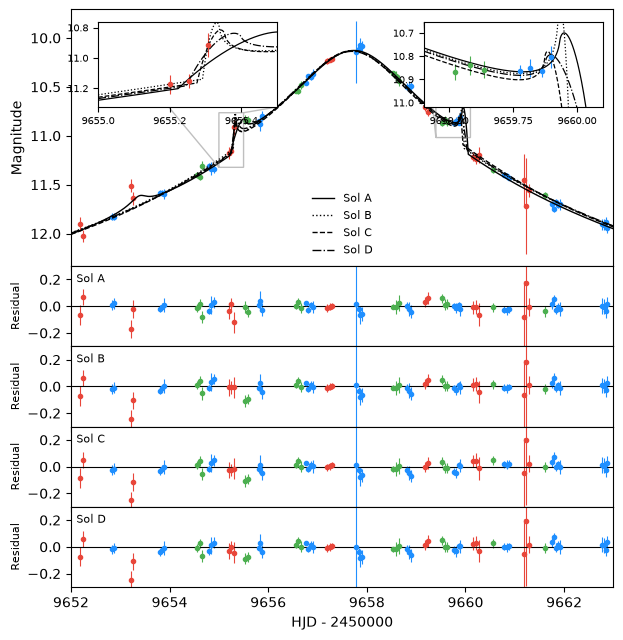

In [5]:
backend = lenscape.make_backend(config.REFINE_BACKEND)
sols = [fits[k][1] for k in "ABCD"]
figures.plot_lightcurve(backend, sols, data, labels=[f"Sol {k}" for k in "ABCD"], window=(9652, 9663),
                        insets=[(9655.0, 9655.5), (9659.4, 9660.1)]);

## Cell fits

`fit_point_box` lets s and q vary inside a cell: a narrow valley that passes between two lattice points is still
found. It returns the best 7-vector inside the cell.

In [6]:
box = (-0.004, 0.006, -2.45, -2.35)          # (log s low, high, log q low, high)
c, x = lenscape.fit.fit_point_box(box, data, cfg)
print(f"best chi2 inside the cell {c:.1f} at log s = {x[5]:.4f}, log q = {x[6]:.3f}")

best chi2 inside the cell 728.1 at log s = 0.0008, log q = -2.436
